In [1]:
import pandas as pd
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
import tensorflow.keras as keras
import numpy as np
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
    classification_report, accuracy_score, precision_score, recall_score,
    f1_score)
import seaborn as sns
import math

/Users/michellebuchiokonicha/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [2]:
# tf.keras.backend.clear_session()

In [3]:
# I got the dataset from kaggle, and it contains the train and test data folders, the sample dataset
vehicle_train_df = pd.read_csv('Emergency_Vehicles/train.csv')
vehicle_train_df

,image_names,emergency_or_not
0,1503.jpg,0
1,1420.jpg,0
2,1764.jpg,0
3,1356.jpg,0
4,1117.jpg,0
...,...,...
1641,1638.jpg,0
1642,1095.jpg,0
1643,1130.jpg,0
1644,1294.jpg,0


In [11]:
# I need to check if the data has null values or not
vehicle_train_df.isnull().sum()

image_names         0
emergency_or_not    0
dtype: int64

In [12]:
vehicle_train_df.value_counts()

image_names  emergency_or_not
0.jpg        1                   1
274.jpg      1                   1
293.jpg      1                   1
292.jpg      1                   1
288.jpg      1                   1
                                ..
1683.jpg     0                   1
1682.jpg     0                   1
1680.jpg     0                   1
1679.jpg     0                   1
999.jpg      0                   1
Name: count, Length: 1646, dtype: int64

In [13]:
print(vehicle_train_df.shape)

(1646, 2)


In [14]:
# I also load the dataset for testing
vehicle_test_df = pd.read_csv('Emergency_Vehicles/test.csv')
vehicle_test_df

,image_names
0,1960.jpg
1,668.jpg
2,2082.jpg
3,808.jpg
4,1907.jpg
...,...
701,674.jpg
702,1027.jpg
703,447.jpg
704,2176.jpg


In [15]:
vehicle_test_df.isnull().sum()

image_names    0
dtype: int64

In [16]:
# I will check the value counts of the test dataset
vehicle_test_df.value_counts()

image_names
100.jpg        1
478.jpg        1
296.jpg        1
297.jpg        1
298.jpg        1
              ..
1745.jpg       1
1747.jpg       1
1750.jpg       1
1760.jpg       1
998.jpg        1
Name: count, Length: 706, dtype: int64

In [17]:
Img_height=64
Img_width = 64
Img_size   = (64, 64)
Batch_size = 32

In [18]:
# defining the width and height of the image for the model build
width_npix, height_npix = 28, 28

In [19]:
# moving back to train, the first thing is to convert the label column to strings. so the ImageGenerator can be used
vehicle_train_df['emergency_or_not'] = vehicle_train_df['emergency_or_not'].astype(str)

In [20]:
# In the emergency_vehlcle folder, there are both the test data folder and the train data folder
train_data = 'Emergency_Vehicles/train'
test_data = 'Emergency_Vehicles/test'

In [21]:
# next, is to define the image transformations that will be used for the data augmentation.
train_datagen = ImageDataGenerator(
    rescale=1./255, validation_split=0.2, rotation_range=20, width_shift_range=0.1, height_shift_range=0.1, horizontal_flip=True, 
    vertical_flip=False, shear_range=0.10, zoom_range=0.10)

In [22]:
# since labels are coming from a CSV, the keras library flow_from_dataframe is best for this case, because of the labels in the csv
vehicle_train_generator = train_datagen.flow_from_dataframe(
    dataframe=vehicle_train_df, directory=train_data, x_col='image_names', y_col='emergency_or_not', target_size=(64, 64),
    batch_size=32, class_mode='binary', subset='training'
)

Found 1317 validated image filenames belonging to 2 classes.


In [23]:
vehicle_train_generator.samples

1317

In [24]:
# now, splitting the data into train, validation, and test, even though it currently has test and train from sklearn model selection
vehicle_train_df, test_and_validate_df = train_test_split(
    vehicle_train_df, test_size=0.3, random_state=123, stratify=vehicle_train_df['emergency_or_not']
)

In [25]:
# now, the test_and_validate_df, I will split it into validation and test for 15% each
vehicle_validate_df, vehicle_test_df = train_test_split(
    test_and_validate_df, test_size=0.3, random_state=123, stratify=test_and_validate_df['emergency_or_not']
)

In [26]:
# since there is no need for augmentation of test and validation dataset, I will just rescale it
validate_and_test_datagen = ImageDataGenerator(rescale=1./255)

In [27]:
# next, we also create the validate generator to enable validate data and information
vehicle_validate_generator = validate_and_test_datagen.flow_from_dataframe(
    dataframe=vehicle_validate_df, directory=train_data, x_col='image_names',y_col='emergency_or_not', target_size=(64, 64), 
    batch_size=32, class_mode='binary'
)

Found 345 validated image filenames belonging to 2 classes.


In [28]:
# next, we also create the test generator to enable test data and information
vehicle_test_generator = validate_and_test_datagen.flow_from_dataframe(
    dataframe=vehicle_test_df, directory=train_data, x_col='image_names',y_col='emergency_or_not', target_size=(64, 64), 
    batch_size=32, class_mode='binary'
)

Found 149 validated image filenames belonging to 2 classes.


# Task b.
* Use the training set from (a), implement a baseline CNN model that includes a Conv2D,with 32 filters, kernel size: 3 × 3, 1 stride length, 
padding: “same”, activation: ReLU, MaxPooling2D with pool size of 2 × 2, with a minimum of 20 training epochs. Evaluatethe model on the 
test set using accuracy, precision and recall. Present results in a clearly structured comparison table and include a confusion matrix and loss curves. 

* In order to implement a baseline CNN model that includes Conv2D, with 32 filters and more, then I will need to use the Sequential approach

In [29]:
# using the Sequential from keras model to create a model
vehicle_model = Sequential()

* for convolutionallayers, I will use the specifications given for the first one that is filters of 32, kernel size of 3,3, strides ,
padding, strides and activation



In [30]:
# creating the first convolutional layer. in subsequent layers, i will try out other hyperparameters so as to tune the model and find the 
# best fit with the color images.
vehicle_model.add(Conv2D(
    filters=32, kernel_size=(3, 3), strides=(1, 1), padding='same', activation='relu', input_shape=(Img_height, Img_width, 3) 
))

/Users/michellebuchiokonicha/Library/Python/3.9/lib/python/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [31]:
# next, for the max pooling layer, I add the model layer
vehicle_model.add(MaxPooling2D(pool_size=(2, 2)))

In [32]:
# next, adding a flatten layer so that the current 2D feature map can now become a 1S vector which will allow to create connected layers
vehicle_model.add(Flatten())

In [33]:
# then I add a dense layer with 64 neurons
vehicle_model.add(Dense(64, activation='relu'))

In [34]:
# the, I add a dropout layer with a rate of 50% so that the overfitting can be reduced. it will purposely dropout some data
vehicle_model.add(Dropout(0.5))

In [35]:
# the next thing is to add the output dense layer and the activation function. I am using sigmoid instead of softmax because it is giving me
# 1 output out of 2 outputs. since softmax likes to analyse more than one neurons and classes, I can't use it here.
vehicle_model.add(Dense(1, activation='sigmoid'))

In [36]:
vehicle_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     2,097,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,098,177 (8.00 MB)

 Trainable params: 2,098,177 (8.00 MB)

 Non-trainable params: 0 (0.00 B)

In [37]:
# next thing is to compile the CNN model using the Adam optimiser,  I will use binary_crossentropy instead of classification _entropy 
# because this is a binary classification since it is only 2 classes with sigmoid
adam_optimizer = Adam(learning_rate=0.001)

In [38]:
# the next thing is to compile the model using the Adam optimizer of 0.001
vehicle_model.compile(optimizer=adam_optimizer, loss='binary_crossentropy', metrics=['accuracy'])

In [88]:
# next is to train the model with 20 epochs and 32 batches
vehicle_history = vehicle_model.fit(vehicle_train_generator, epochs=20, validation_data=vehicle_validate_generator)

Epoch 1/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.6040 - loss: 0.6603 - val_accuracy: 0.6957 - val_loss: 0.6372
Epoch 2/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.6118 - loss: 0.6607 - val_accuracy: 0.7159 - val_loss: 0.5880
Epoch 3/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.6045 - loss: 0.6294 - val_accuracy: 0.7217 - val_loss: 0.5792
Epoch 4/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.6505 - loss: 0.6118 - val_accuracy: 0.6986 - val_loss: 0.5519
Epoch 5/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.6677 - loss: 0.6057 - val_accuracy: 0.7594 - val_loss: 0.5110
Epoch 6/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.6546 - loss: 0.5923 - val_accuracy: 0.7275 - val_loss: 0.5500
Epoch 7/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.6446 - loss: 0.6019 - val_accuracy: 0.7623 - val_loss: 0.5223
Epoch 8/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.6400 - loss: 0.6045 - val_accuracy: 0.7710 - v

In [42]:
# now, inorder to plot the charts, I will use the history from the pandas
vehicle_history_df = pd.DataFrame(vehicle_history.history)

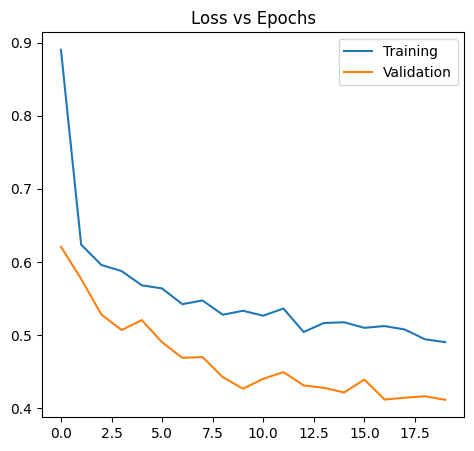

In [43]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(vehicle_history_df['loss'], label='Training')
plt.plot(vehicle_history_df['val_loss'], label='Validation')
plt.title('Loss vs Epochs')
plt.legend()
plt.show()

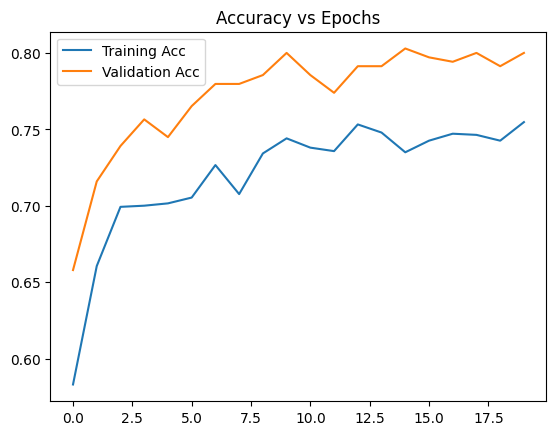

In [44]:
plt.plot(vehicle_history_df['accuracy'], label='Training Acc')
plt.plot(vehicle_history_df['val_accuracy'], label='Validation Acc')
plt.title('Accuracy vs Epochs')
plt.legend()
plt.show()

In [ ]:
# saving the plots are images 1 and 2 - Buchi, do this
# plt.savefig('loss_curves.png', dpi=150)


* next thing is to predict on the test set. 
before predicting, it is important that I reset the generator for testing since the images are stored on my disk and the testing generator
will be reading them one batch at a time, so I need to reset before predicting

In [45]:
# now, inorder to reset the test, I will use the reset function from keras
vehicle_test_generator.reset()

In [46]:
# then now, I will proceed with predicting so I can evaluate the model with the test set
vehicle_pred = vehicle_model.predict(vehicle_test_generator)
#  that the vehicle prediction is greater than 50% and making it an integer
vehicle_pred_class = (vehicle_pred > 0.5).astype(int).flatten()

5/5 ━━━━━━━━━━━━━━━━━━━━ 32s 8s/step


In [47]:
# next, to define the true labels that are gotten from the test generator
vehicle_y_true = vehicle_test_df['emergency_or_not'].astype(int).values

* now that I have gottent the labels and also evaluated the model with the test set, I move to the confusion matrix

In [51]:
# defining the initial  matrix
vehicle_con_mat = confusion_matrix(vehicle_y_true, vehicle_pred_class)

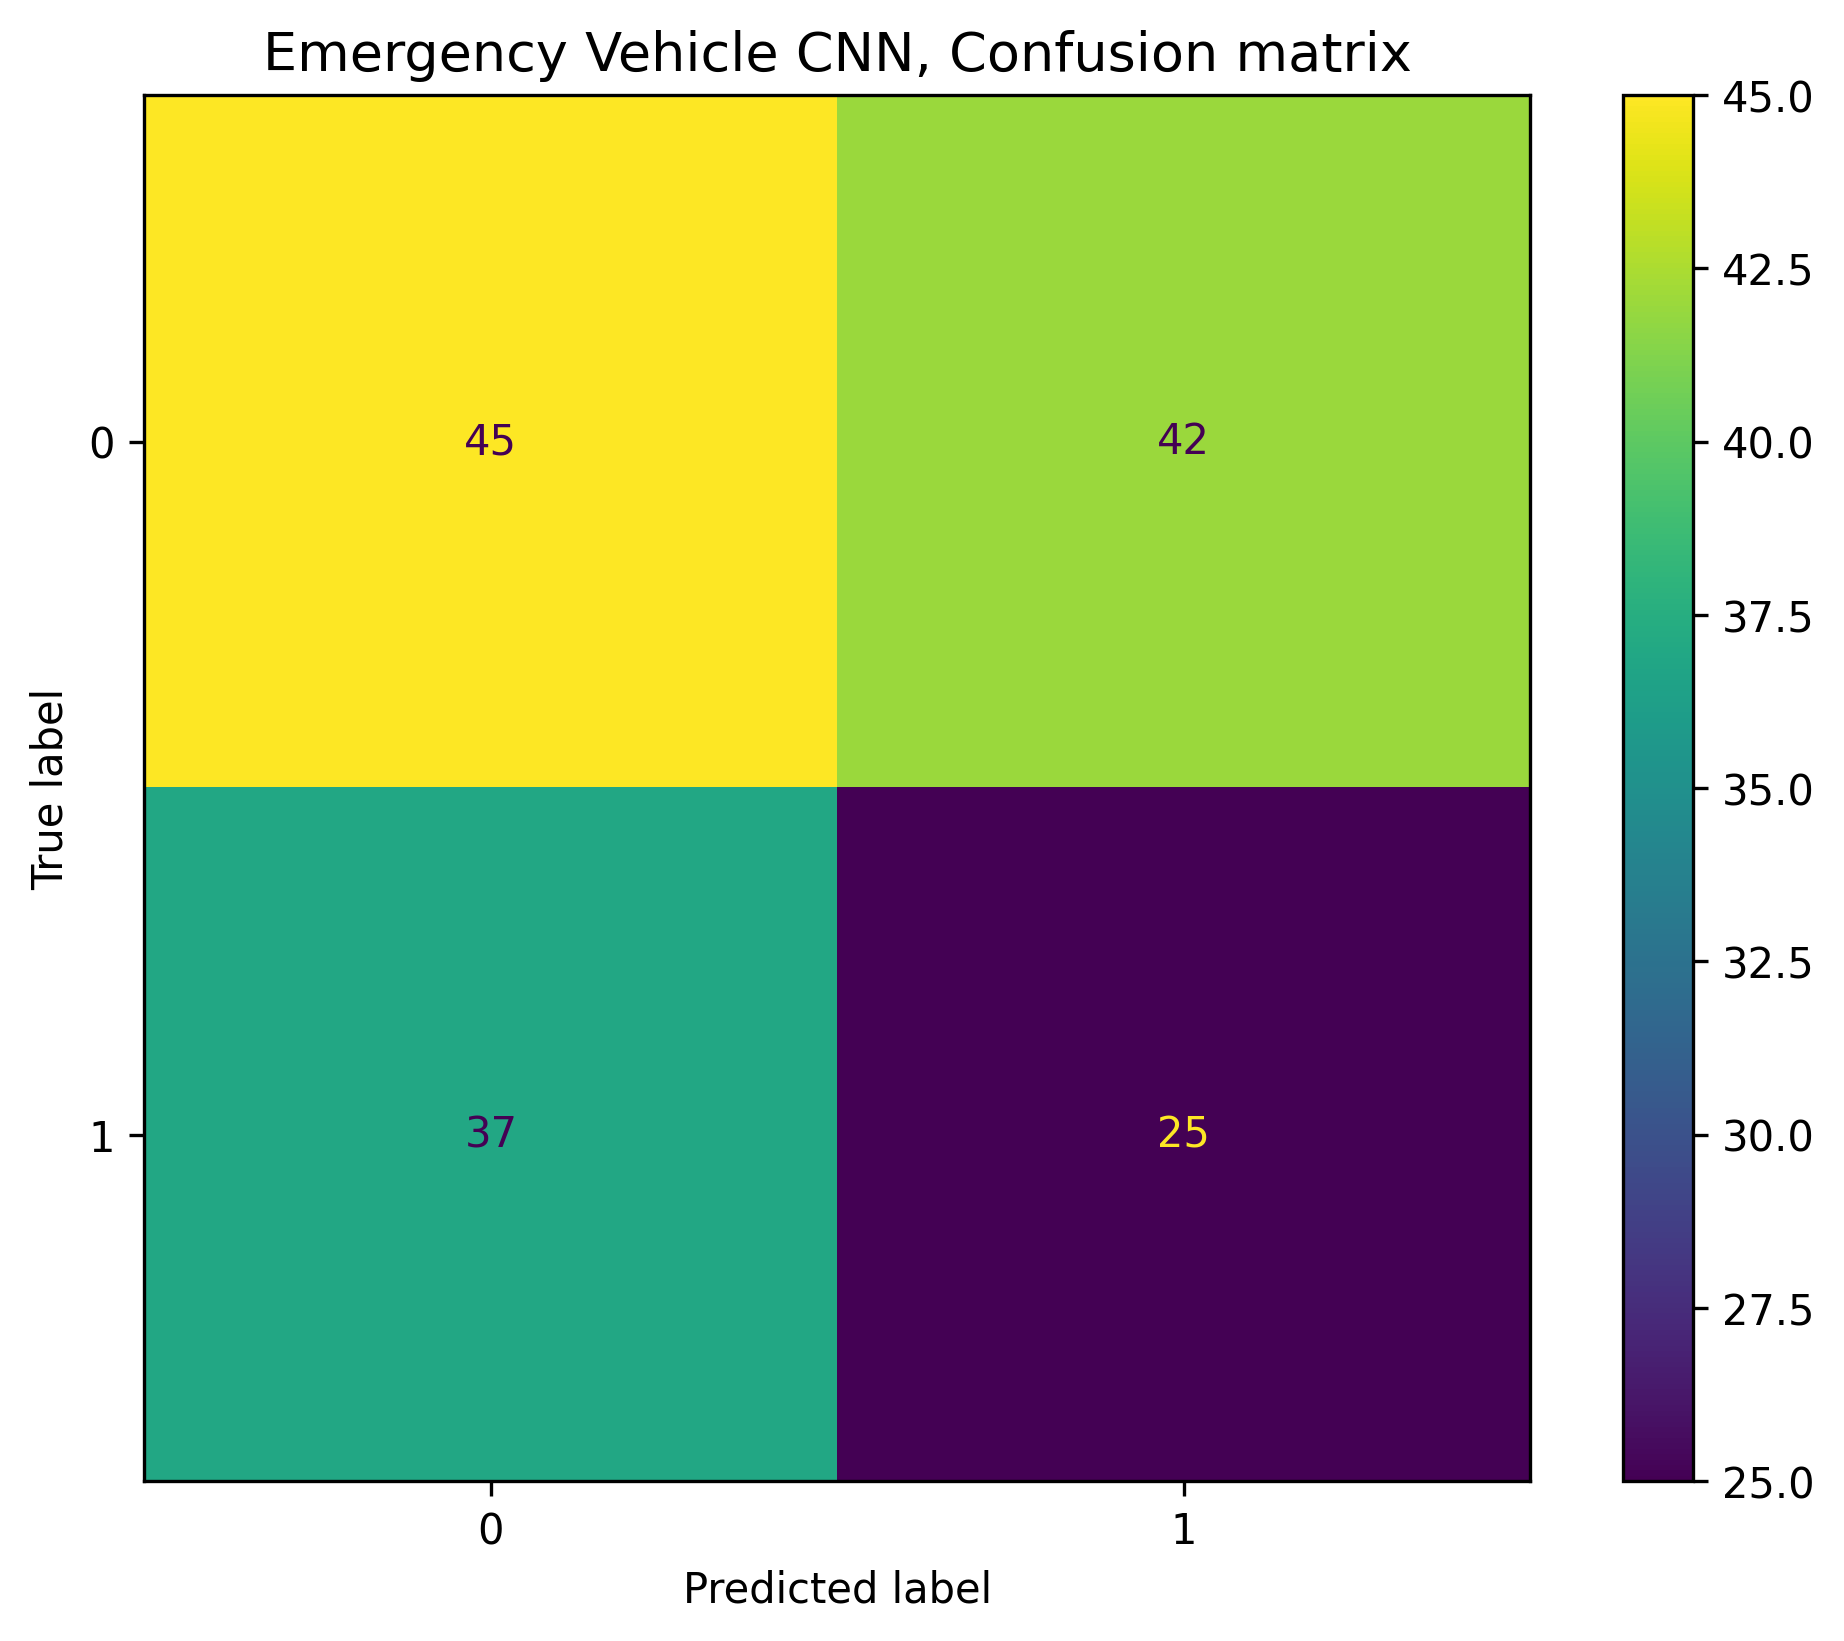

In [62]:
# now, plotting the chart
plt.figure(figsize=(8, 6), dpi=300)
ax = plt.axes()
disp = ConfusionMatrixDisplay(confusion_matrix=vehicle_con_mat)
# disp = ConfusionMatrixDisplay(confusion_matrix=vehicle_con_mat, display_labels=['Non-Emergency', 'Emergency'])
disp.plot(ax=ax)
plt.title('Emergency Vehicle CNN, Confusion matrix', fontsize=13)
# plt.xlabel('Predicted Label')
# plt.ylabel('True Label', fontsize=11)
plt.savefig('emergency_vehicle_confusion_matrix.png', dpi=150)
plt.show()


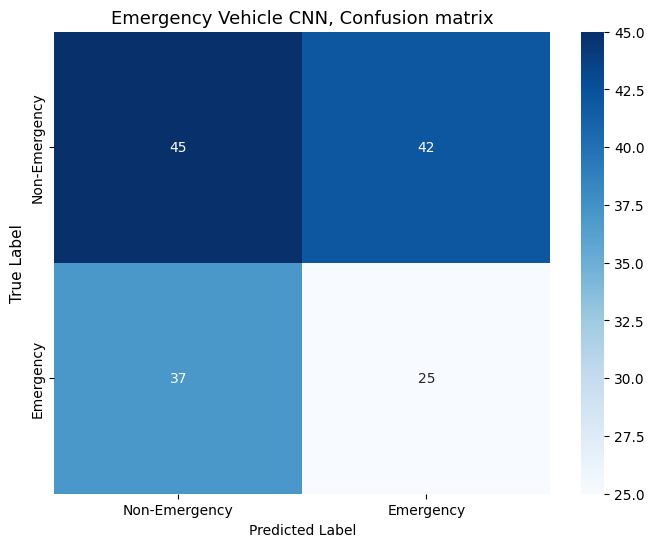

In [64]:
# plotting it with seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(vehicle_con_mat, annot=True, fmt='d', cmap='Blues', xticklabels=['Non-Emergency', 'Emergency'],
            yticklabels=['Non-Emergency', 'Emergency'])
plt.title('Emergency Vehicle CNN, Confusion matrix', fontsize=13)
plt.xlabel('Predicted Label')
plt.ylabel('True Label', fontsize=11)
plt.savefig('emergency_vehicle_confusion_matrix.png', dpi=150)
plt.show()
                                                                                

In [68]:
 # now, the next step is to get the accuracy, precision, and recall
print("Emergency Vehicle CNN for classification:")
print(classification_report(vehicle_y_true, vehicle_pred_class, target_names=['Non-Emergency', 'Emergency']))

Emergency Vehicle CNN for classification:
               precision    recall  f1-score   support

Non-Emergency       0.55      0.52      0.53        87
    Emergency       0.37      0.40      0.39        62

     accuracy                           0.47       149
    macro avg       0.46      0.46      0.46       149
 weighted avg       0.48      0.47      0.47       149



In [74]:
vehicle_emergency_accuracy = round(accuracy_score(vehicle_y_true, vehicle_pred_class), 4)
vehicle_emergency_precision = round(precision_score(vehicle_y_true, vehicle_pred_class), 4)
vehicle_emergency_recall = round(recall_score(vehicle_y_true, vehicle_pred_class), 4)
vehicle_emergency_f1 = round(f1_score(vehicle_y_true, vehicle_pred_class), 4)

In [75]:
emergency_vehicle_final_result = pd.DataFrame([{
    'Model': 'Emergency Vehicle CNN',
    'Accuracy': vehicle_emergency_accuracy,
    'Precision': vehicle_emergency_precision,
    'Recall': vehicle_emergency_recall,
    'F1 Score': vehicle_emergency_f1
}])
display(emergency_vehicle_final_result)

,Model,Accuracy,Precision,Recall,F1 Score
0,Emergency Vehicle CNN,0.4698,0.3731,0.4032,0.3876



* Result so far

* So far, the results I have gotten in task B are:
accuracy: 0.47
Precision: 0.37
Recall: 0.40
F1: 0.39

* Confusion Matrix: 45 for the correct non-emergency, then for the correct emergency, it's just 25. 
    Then there are also 42 and 37, which are misclassifications


* This result is a weak baseline because I only used one Conv2D layer instead of at least 2 or 3. Using one made it not deep enough to learn
complex features. I also did not use batch normalization here, so the training is not stable because of that. 
* Also, I don't have multiple convolutional blocks, hence, it is missing the feature hierarchy
* The other thing is that the model is not stable because the validation loss is high

# Task C

c. Develop a second CNN model with a custom architecture using the same training set in
(a). You must introduce at least one regularisation technique and apply hyperparameter
tuning as applicable. Ensure to justify your architectural and tuning choices briefly.
Compare the performance of the custom model with the baseline model using a
structured results table. 

* *My Approach*

  
* Now, I will be developing a second model using custom architecture. Here, I will use 3 Convolution layers and also include
  BatchNormalization and reduce the learning rate. I will also try to increase the neurons, and I will add a Dropout layer so this model
  does not overfit.
* To begin, I will clear the session so that the layer names won't conflict and so that the weights I used before won't affect this new one
  I am building a model to ensure the old model is no longer in RAM.

In [40]:
# to clear the session, I will use the keras clear_session() function
tf.keras.backend.clear_session()

In [41]:
# here, I will create the new model with Sequential()
vehicle_custom_model = Sequential()

In [42]:
# here, repeating the convolutional block with 32 filters
vehicle_custom_model.add(Conv2D(
    filters=32, kernel_size=(3, 3), strides=(1, 1), padding='same', input_shape=(Img_height, Img_width, 3), activation='relu'))

* this part is for batchNormalization. this is because it helps to normalize the outputs to actual 1s and 0s values. mean=0, std=1 and
hence, it works to make training stable and the convergence becomes faster.

In [43]:
# to standardize the training data, batchNormalization from keras
vehicle_custom_model.add(BatchNormalization())

# then using MaxPooling
vehicle_custom_model.add(MaxPooling2D(pool_size=(2, 2)))

* Now, I move to the second convolutional layer with Conv2D, but here, I will use 64 filters as opposed to the previous 32, so that it can learn shapes and texture,
mid-level features since the first convolutional layer was learning edges and colors for low-level features


In [44]:
# using 64 filters, for layer 2
vehicle_custom_model.add(Conv2D(filters=64, kernel_size=(3, 3), strides=(1, 1), padding='same', activation='relu'))

In [45]:
# now, including the batchNormalization
vehicle_custom_model.add(BatchNormalization())
vehicle_custom_model.add(MaxPooling2D(pool_size=(2, 2)))

In [46]:
# adding a Dropout layer so there is no overfitting
vehicle_custom_model.add(Dropout(0.25))

* now, for the third convolutional layer, I will use 128 filters so it use the high level features to learn and understand the shape of
the vehicle as well as the markings that indicate emergency or no emergency

In [47]:
# using 128 filters
vehicle_custom_model.add(Conv2D(filters=128, kernel_size=(3, 3), strides=(1, 1), padding='same', activation='relu'))

In [48]:
# also standardizing it by normalizing and stabilizing it with batchNormalization
vehicle_custom_model.add(BatchNormalization())

In [49]:
# adding the MaxPooling2D layer
vehicle_custom_model.add(MaxPooling2D(pool_size=(2, 2)))

In [50]:
# adding the dropout layer of 25% to prevent overfitting
vehicle_custom_model.add(Dropout(0.25))

In [51]:
# next, implimenting the fully connected layers by flattening it, adding dense layers andstabilizing it
vehicle_custom_model.add(Flatten())

In [52]:
# using 128 layes for the hidden layer relu
vehicle_custom_model.add(Dense(128, activation='relu'))

In [53]:
# normalizing the model
vehicle_custom_model.add(BatchNormalization())

In [54]:
# using a higher dropout rate of 50% because this is the dense layer
vehicle_custom_model.add(Dropout(0.5))

In [55]:
# for the output layer, using sigmoid since it's a binary classification
vehicle_custom_model.add(Dense(1, activation='sigmoid'))

In [56]:
# reading through the summary to get a full picture of the results
vehicle_custom_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,143,489 (4.36 MB)

 Trainable params: 1,142,785 (4.36 MB)

 Non-trainable params: 704 (2.75 KB)

* Inorder to compile this new model, I will reduce the learning rate from 0.01 to 0.001 as part of the hyperparameter so I can get better
results and also ensure the model fits better this time

In [57]:
# defining the adam optimizer with a lower learning rate
adam_optimizer=Adam(learning_rate=0.0001)

In [58]:
# compiling the model
vehicle_custom_model.compile(optimizer=adam_optimizer, loss='binary_crossentropy', metrics=['accuracy'])

In [59]:
# In order to train this model, I will stick with the same epoch of 20 so I can better analyse and compare the results with the previous
vehicle_custom_history = vehicle_custom_model.fit(vehicle_train_generator, epochs=20, validation_data=vehicle_validate_generator)

Epoch 1/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 124s 3s/step - accuracy: 0.5697 - loss: 0.9397 - val_accuracy: 0.5884 - val_loss: 0.6600
Epoch 2/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 84ms/step - accuracy: 0.6630 - loss: 0.7295 - val_accuracy: 0.5884 - val_loss: 0.7469
Epoch 3/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 72ms/step - accuracy: 0.6795 - loss: 0.7175 - val_accuracy: 0.5884 - val_loss: 1.0650
Epoch 4/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step - accuracy: 0.6747 - loss: 0.6900 - val_accuracy: 0.5884 - val_loss: 1.1349
Epoch 5/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 73ms/step - accuracy: 0.7137 - loss: 0.6561 - val_accuracy: 0.5884 - val_loss: 0.8261
Epoch 6/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 72ms/step - accuracy: 0.6977 - loss: 0.6420 - val_accuracy: 0.6174 - val_loss: 0.7134
Epoch 7/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 92ms/step - accuracy: 0.7388 - loss: 0.6012 - val_accuracy: 0.6841 - val_loss: 0.6469
Epoch 8/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 89ms/step - accuracy: 0.7225 - loss: 0.6022 - val_accuracy: 0.7507 - v

* The next thing to do is to plotting the loss curves

In [62]:
# here, 
vehicle_custom_history_df = pd.DataFrame(vehicle_custom_history.history)

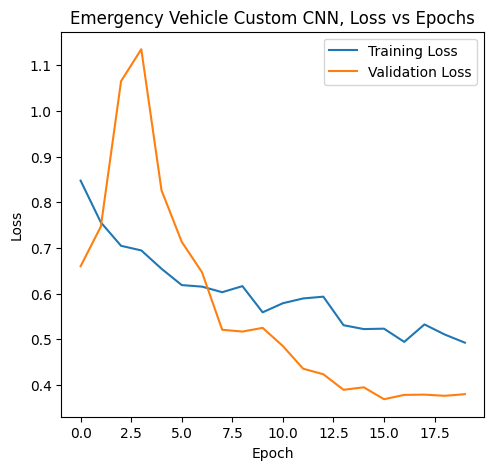

In [63]:
# the plotting the curves
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(vehicle_custom_history_df['loss'], label='Training Loss')
plt.plot(vehicle_custom_history_df['val_loss'], label='Validation Loss')
plt.title('Emergency Vehicle Custom CNN, Loss vs Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.savefig('emergency_vehicle_custom_loss_epoch.png', dpi=150)
plt.show()

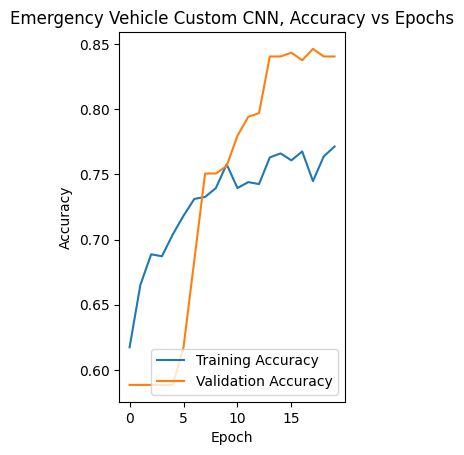

In [65]:
plt.subplot(1, 2, 2)
plt.plot(vehicle_custom_history_df['accuracy'], label='Training Accuracy')
plt.plot(vehicle_custom_history_df['val_accuracy'], label='Validation Accuracy')
plt.title('Emergency Vehicle Custom CNN, Accuracy vs Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.savefig('emergency_vehicle_custom_accuracy_epoch.png', dpi=150)

plt.show()

* The next thing to do, similar to the first model is to use the test set to evaluate this new model and hence, having to rest the test
generator

In [66]:
# first, resetting the test generator
vehicle_test_generator.reset()

In [67]:
# then predicting the model using this test generator and creating the predict class
vehicle_custom_pred = vehicle_custom_model.predict(vehicle_test_generator)
vehicle_custom_pred_class = (vehicle_custom_pred > 0.5).astype(int).flatten()

5/5 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step


In [69]:
# now difining the labels for this model
vehicle_custom_y_true = vehicle_test_df['emergency_or_not'].astype(int).values

* This step is for the confusion matrix. this will give a clear picture of the results and if the model is strong or weak 

In [72]:
vehicle_custom_con_mat = confusion_matrix(vehicle_custom_y_true, vehicle_custom_pred_class)

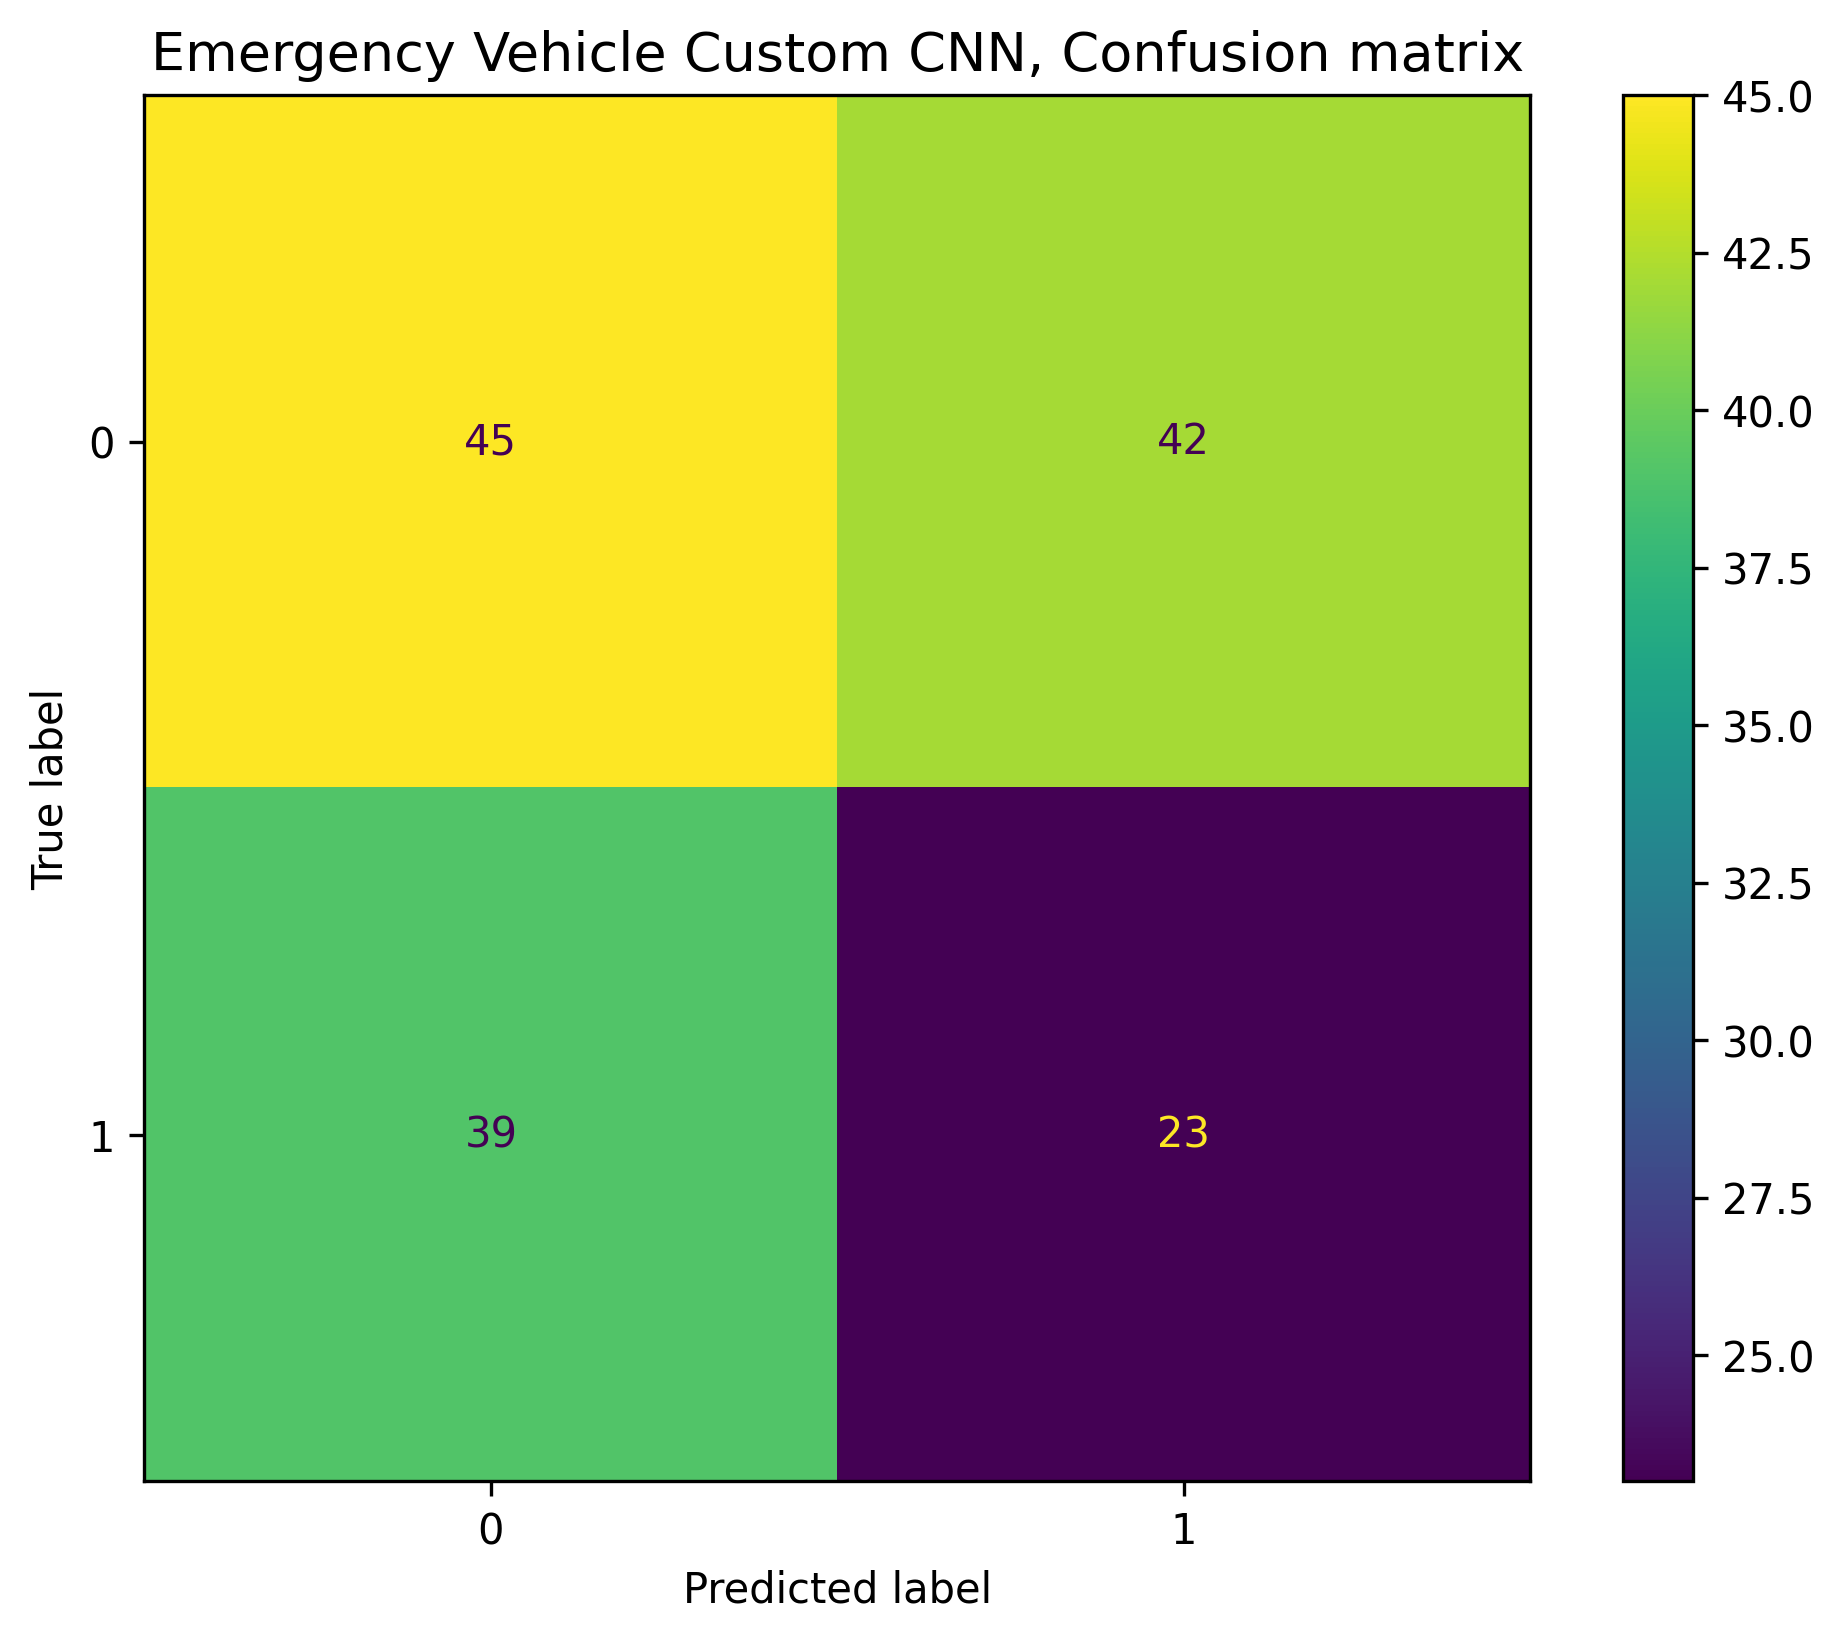

In [73]:
# now, plotting the chart
plt.figure(figsize=(8, 6), dpi=300)
ax = plt.axes()
disp = ConfusionMatrixDisplay(confusion_matrix=vehicle_custom_con_mat)
# disp = ConfusionMatrixDisplay(confusion_matrix=vehicle_custom_con_mat, display_labels=['Non-Emergency', 'Emergency'])
disp.plot(ax=ax)
plt.title('Emergency Vehicle Custom CNN, Confusion matrix', fontsize=13)
# plt.xlabel('Predicted Label')
# plt.ylabel('True Label', fontsize=11)
plt.savefig('emergency_vehicle_custom_confusion_matrix.png', dpi=150)
plt.show()


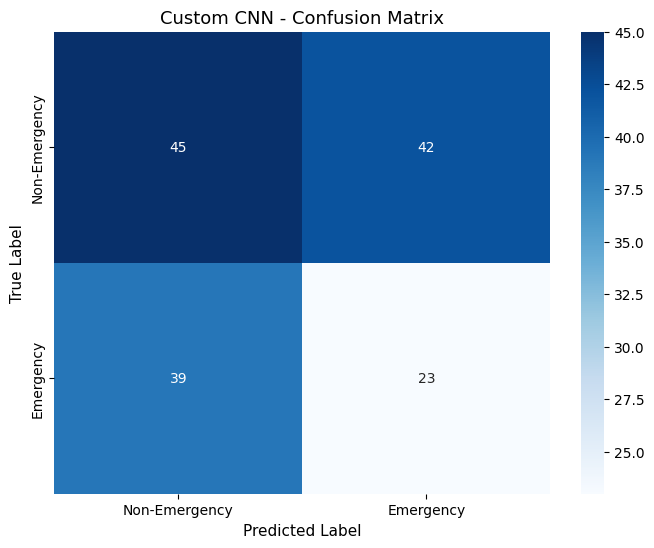

In [75]:
# working with seaborn as well
plt.figure(figsize=(8, 6))
sns.heatmap(vehicle_custom_con_mat, annot=True, fmt='d',cmap='Blues', xticklabels=['Non-Emergency', 'Emergency'],
            yticklabels=['Non-Emergency', 'Emergency'])
plt.title('Custom CNN - Confusion Matrix', fontsize=13)
plt.xlabel('Predicted Label', fontsize=11)
plt.ylabel('True Label', fontsize=11)
# plt.tight_layout()
plt.savefig('vehicle_custom_confusion_matrix2.png', dpi=150)
plt.show()

* Figures and data inorder to classify this new model and get results to compare with previous model

In [76]:
# the report for classification to get the information about the custom model
print(classification_report(vehicle_custom_y_true, vehicle_custom_pred_class, target_names=['Non-Emergency', 'Emergency']))

               precision    recall  f1-score   support

Non-Emergency       0.54      0.52      0.53        87
    Emergency       0.35      0.37      0.36        62

     accuracy                           0.46       149
    macro avg       0.44      0.44      0.44       149
 weighted avg       0.46      0.46      0.46       149



In [77]:
# next, is to create the metrics of the initial model created
vehicle_pred = vehicle_model.predict(vehicle_test_generator)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


In [78]:
# then to reset the generator
vehicle_test_generator.reset()

In [82]:
# next, to define the true labels that are gotten from the test generator
vehicle_y_true = vehicle_test_df['emergency_or_not'].astype(int).values

In [79]:
# next, to create a prediction class
vehicle_pred_class = (vehicle_pred > 0.5).astype(int).flatten()

In [84]:
# now, I will create the table for comparison of the two models
emergency_vehicle_comparison = pd.DataFrame([
    {
    'Model': 'Emergency Vehicle CNN',
    'Architecture': '1 Conv Block, No BatchNormalization',
    'Regularisation': 'Dropout(0.5)',
    'Learning Rate': 0.001,
    'Accuracy':   round(accuracy_score(vehicle_y_true, vehicle_pred_class), 4),
    'Precision':  round(precision_score(vehicle_y_true, vehicle_pred_class), 4),
    'Recall':     round(recall_score(vehicle_y_true, vehicle_pred_class), 4),
    'F1 Score':   round(f1_score(vehicle_y_true, vehicle_pred_class), 4)
     },
    {
        'Model':      'Emergency Vehicle Custom CNN',
        'Architecture': '3 Conv Blocks, BatchNorm',
        'Regularisation': 'BatchNorm + Dropout(0.25/0.5)',
        'Learning Rate': 0.0001,
        'Accuracy':   round(accuracy_score(vehicle_custom_y_true, vehicle_custom_pred_class), 4),
        'Precision':  round(precision_score(vehicle_custom_y_true, vehicle_custom_pred_class), 4),
        'Recall':     round(recall_score(vehicle_custom_y_true, vehicle_custom_pred_class), 4),
        'F1 Score':   round(f1_score(vehicle_custom_y_true, vehicle_custom_pred_class), 4)
    }
])


In [85]:
display(emergency_vehicle_comparison)

,Model,Architecture,Regularisation,Learning Rate,Accuracy,Precision,Recall,F1 Score
0,Emergency Vehicle CNN,"1 Conv Block, No BatchNormalization",Dropout(0.5),0.0010,0.5302,0.4091,0.2903,0.3396
1,Emergency Vehicle Custom CNN,"3 Conv Blocks, BatchNorm",BatchNorm + Dropout(0.25/0.5),0.0001,0.4564,0.3538,0.3710,0.3622


# Task d.
    
* Critically interpret the performance of both models. You must include: training vs
validation loss plots, confusion matrix visualisation, classification report etc. Evaluate
whether overfitting or underfitting is evident, supporting your reasoning with visual and
metric-based evidence.